# Fundamentals

Machine learning fundamental tools exploration along with experiments for observing and understanding critical operations with the tools, along with crafting solution with those tools along the way.

### Targets to complete
1. Learn fundamental operations with dataset
2. Referencing with correct non-curropted data flow designs
3. Pandas most essential tooling guide
4. Data handle with full fledge EDA pipeline with sample dataset


---

### Fundamentals with pandas

A comprehensive powerhouse for handling dataset, inspecting details, utility functions for targeted selections and usefull operations
to derive comprehensive understanding of dataset. With pandas api we have full flexible controll with dataset, with consistent simple pythic interface, it becomes really easy to manupulate dataset.

#### Indexing details with pandas

Foundational rules with using indexing from pandas resources
- Using optimized pathway with pandas would be way faster to implement operations with data frame
- Endpoints in indexing is inclusive in pandas indexing
- A boolean array (NA) is termed as False

### Experimentation targets with pandas
1. Apply aggregations to series
    - Bining
    - Averaging
    - Statistical measure
    - Grouping features plot
2. Fetch other information from the core function
3. Compose new feature with existing features through pandas
4. Make relation of the features with the target with out loosing grip

### Learning objective
+ Foundations of pandas
+ Indexing preservance
+ confident data operations

In [43]:
import pandas as pd

df = pd.read_csv("/home/madhav/workstation/Lab/experiment/data/gaming.csv")

df = df.dropna() # Null drop
''' 
With null droping we drop the whole row,
thus we get the final truncated result from the dataset
'''
df.info()

<class 'pandas.DataFrame'>
Index: 7090 entries, 2 to 9999
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PlayerID                   7090 non-null   int64  
 1   Age                        7090 non-null   float64
 2   Gender                     7090 non-null   str    
 3   Location                   7090 non-null   str    
 4   GameGenre                  7090 non-null   str    
 5   PlayTimeHours              7090 non-null   float64
 6   InGamePurchases            7090 non-null   float64
 7   GameDifficulty             7090 non-null   str    
 8   SessionsPerWeek            7090 non-null   int64  
 9   AvgSessionDurationMinutes  7090 non-null   int64  
 10  PlayerLevel                7090 non-null   int64  
 11  AchievementsUnlocked       7090 non-null   int64  
 12  EngagementLevel            7090 non-null   str    
dtypes: float64(3), int64(5), str(5)
memory usage: 775.5 KB


<BarContainer object of 9 artists>

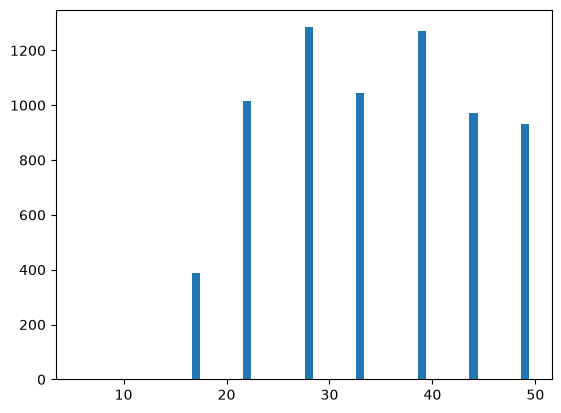

In [44]:
# What is the age distribution with the dataset ?
import matplotlib.pyplot as plt
import numpy as np

'''
With manual gearing for finding the distribution,
or relation of age could be fragiel
Just with one tweak of adjusting the sorting of ages
we can alter the graph to represent wrong thing,

Indexing is also not tighted with the data values, 
raising more concern with the dataset flow :)

Thus we can use pandas native approach to handle indexing and grouping, 
based graph which could walk through with indexing while we sort the values
'''     
age_info = np.array(df["Age"])

# Numerical bins for numbers
size = 10
bins = np.ceil(np.linspace(0, age_info.max(), num=size))

age_freq = []
prev = 0

for bin in bins[1:]:
    condition = (df['Age'] >= prev) & (df['Age'] < bin)
    fetch = df[condition]
    count = len(fetch)
    age_freq.append(count)
    prev = bin
    
X = bins[1:]
plt.bar(X, age_freq)

<Axes: xlabel='Age'>

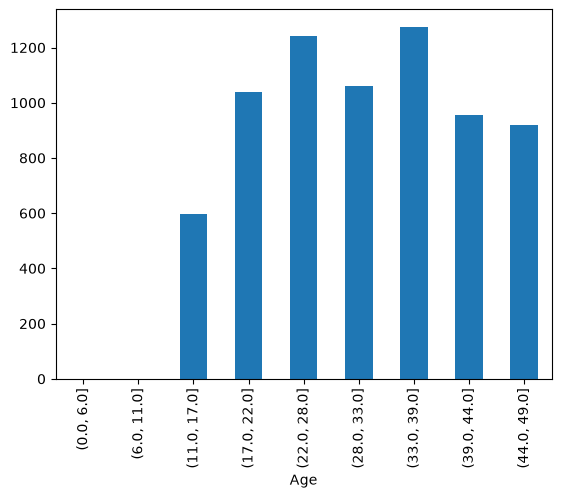

In [58]:
'''
Testing index boundations with pandas, 
binning view based approach for age distribution inspection 
With pandas based implementation would
be safe against age sorting, since its made through native cut method
to handle save with custom binning rages
'''
age = df['Age'].copy(deep=True)

bins = np.ceil(
    np.linspace(0, age.max(), 10)
)
age_groups =  pd.cut(age, bins=bins)
# Defaults sorts with values plot | can alter with turning off with sort switch
bin_counts = age_groups.value_counts(sort=False)
bin_counts.plot(kind='bar')

EngagementLevel
High      369.0
Low       364.0
Medium    711.0
Name: InGamePurchases, dtype: float64


Text(0, 0.5, 'sum of in game purchase')

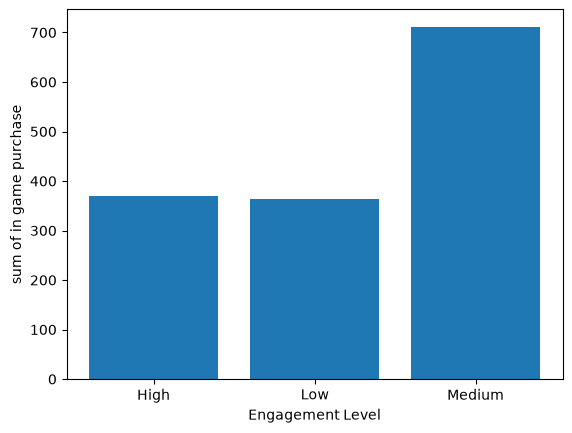

In [48]:
'''
Relation of features with the root target variable
With aggregation functions with the root column along with features, 
we can expose the relation

How does AvgSessionDurationMinutes is related to EngagementLevel ?

Approach
plot local avg trend with the engagement levels

+ InGamePurchases 
What is the relation of purchase with the engagement and playtime 
'''

purchase_groups = df.groupby('EngagementLevel')['InGamePurchases'].sum()
print(purchase_groups)
X = purchase_groups.index
y = purchase_groups


plt.bar(X,y)
plt.xlabel('Engagement Level')
plt.ylabel('sum of in game purchase')

In [ ]:
# Binning in game purchasing people into categories
purchase_data = df['InGamePurchases']



2       0.0
4       1.0
6       0.0
9       0.0
10      1.0
       ... 
9995    0.0
9996    0.0
9997    0.0
9998    0.0
9999    1.0
Name: InGamePurchases, Length: 7090, dtype: float64